# 05c — CatBoost: chọn đặc trưng bằng HCO, VNLS và HCO–VNLS

**Câu hỏi:** Khi model chấm mask là CatBoost **xử lý category gốc**, tập đặc trưng chọn bởi ba cách tìm khác nhau có giữ được chất lượng dự đoán không?

Thí nghiệm này **không** lấy điểm CatBoost 240 cây của notebook 04 làm đối chứng trực tiếp. Mọi hàng dưới đây đều dùng CatBoost 80 cây, cùng split theo `id_student`, cutoff 50%/75%, `alpha=0,85`, seed 41, ngân sách tối đa 8 mask chưa cache. Mask chỉ được tìm trong train qua 3-fold GroupKFold; validation chỉ để đối chiếu sau tìm kiếm. Không dùng test để điều chỉnh.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from catboost import CatBoostClassifier
import catboost

ROOT = Path.cwd()
if not (ROOT / 'clht_code').exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
from NghienCuu_HCO_VNLS.code_dung_chung.thuc_nghiem import KET_QUA, HINH, nap_du_lieu, chon_dac_trung, tao_thu_muc
from clht_code.evaluation import metric_table
from clht_code.optimizers import run_search_budgeted, fitness

tao_thu_muc()
print('CatBoost', catboost.__version__, '| nguồn dữ liệu:', KET_QUA)

CatBoost 1.2.10 | nguồn dữ liệu: CLHT_GB_GITHUB\NghienCuu_HCO_VNLS\ket_qua


## 1. CatBoost nhìn dữ liệu như thế nào?

Mỗi cột chữ được thay giá trị thiếu bằng chuỗi `THIEU`, giữ nguyên dạng category và truyền danh sách `cat_features` vào CatBoost. Các cột số giữ giá trị thiếu dưới dạng NaN để CatBoost tự xử lý. **Tuyệt đối không đưa `risk`, `split` hoặc `id_student` vào tập đặc trưng.** Chỉ fitting model trên train của mỗi fold; validation của fold có cùng cách xử lý category nhưng không tham gia fit.

So với LightGBM ở notebook 05b dùng pipeline OneHotEncoder, cách tiếp cận này giữ lợi thế xử lý category gốc của CatBoost. Đó cũng là một khác biệt trong evaluator: chỉ so **tác động của chọn cột trong cùng CatBoost**, không quy chênh lệch CatBoost–LightGBM cho riêng optimizer.

In [2]:
CONFIG = dict(iterations=80, depth=5, learning_rate=.055, l2_leaf_reg=5,
              loss_function='Logloss', verbose=False, thread_count=4,
              random_seed=41, allow_writing_files=False)

def prepare_categories(frame, category_columns):
    clean = frame.copy()
    for column in category_columns:
        clean[column] = clean[column].fillna('THIEU').astype(str)
    return clean

def fit_predict(train_x, train_y, valid_x):
    category_columns = train_x.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
    model = CatBoostClassifier(**CONFIG)
    model.fit(prepare_categories(train_x, category_columns), train_y,
              cat_features=category_columns)
    return model.predict_proba(prepare_categories(valid_x, category_columns))[:, 1]

class CatBoostMaskObjective:
    def __init__(self, frame, y, groups, alpha=.85):
        self.frame = frame
        self.y = np.asarray(y)
        self.groups = np.asarray(groups)
        self.alpha = alpha
        self.cache = {}
        self.calls = 0
        self.cache_hits = 0

    def __call__(self, mask):
        key = tuple(np.asarray(mask, dtype=np.int8))
        if key in self.cache:
            self.cache_hits += 1
            return self.cache[key]
        selected = self.frame.columns[np.flatnonzero(mask)].tolist()
        if not selected:
            return 0.0, 0.0
        ap_folds = []
        for train_idx, valid_idx in GroupKFold(n_splits=3).split(self.frame, self.y, self.groups):
            probability = fit_predict(self.frame.iloc[train_idx][selected], self.y[train_idx],
                                      self.frame.iloc[valid_idx][selected])
            ap_folds.append(average_precision_score(self.y[valid_idx], probability))
        ap_cv = float(np.mean(ap_folds))
        result = (fitness(ap_cv, len(selected), self.frame.shape[1], self.alpha), ap_cv)
        self.cache[key] = result
        self.calls += 1
        return result

print('Cấu hình chung:', CONFIG)

Cấu hình chung: {'iterations': 80, 'depth': 5, 'learning_rate': 0.055, 'l2_leaf_reg': 5, 'loss_function': 'Logloss', 'verbose': False, 'thread_count': 4, 'random_seed': 41, 'allow_writing_files': False}


## 2. Chấm cả bộ đầy đủ và ba cách tìm mask

Với `K=38`, mỗi mask là 38 bit. Fitness = `0,85 × AP_cv + 0,15 × (1 - k/38)`; `k` là số cột đang giữ. Hàng **Full features** là CatBoost 80 cây không chọn cột. HCO/VNLS/hybrid có cùng evaluator và ngân sách. Một pilot nhỏ và một seed chỉ giúp nhìn xu hướng, **không** chứng minh thuật toán đã tối ưu toàn cục hay từng cột có ý nghĩa nhân quả.

In [3]:
rows, traces = [], []
for cutoff in (.50, .75):
    frame = nap_du_lieu(cutoff)
    columns = chon_dac_trung(frame)
    train, valid = (frame.loc[frame.split == split].copy() for split in ('train', 'validation'))
    assert not (set(train.id_student) & set(valid.id_student))
    x_train, x_valid = train[columns], valid[columns]
    print(f'Cutoff {cutoff:.0%}: {len(train)} train, {len(valid)} validation, {len(columns)} cột')
    started = time.perf_counter()
    full_prob = fit_predict(x_train, train.risk, x_valid)
    rows.append(dict(cutoff=cutoff, method='Full features', features=len(columns),
                     fitness_cv=np.nan, ap_cv=np.nan, objective_calls=0,
                     search_seconds=0.0, fit_seconds=time.perf_counter() - started,
                     selected_columns='|'.join(columns),
                     **metric_table(valid.risk, full_prob, .5)))
    for method in ('HCO', 'VNLS', 'HCO-VNLS'):
        objective = CatBoostMaskObjective(x_train, train.risk.to_numpy(), train.id_student.to_numpy())
        search = run_search_budgeted(method, objective, seed=41, budget=8, population=3)
        selected = search['selected_columns']
        started = time.perf_counter()
        probability = fit_predict(x_train[selected], train.risk, x_valid[selected])
        row = dict(cutoff=cutoff, method=method, features=len(selected),
                   fitness_cv=search['fitness_cv'], ap_cv=search['average_precision_cv'],
                   objective_calls=search['objective_calls'], search_seconds=search['wall_seconds'],
                   fit_seconds=time.perf_counter()-started, selected_columns='|'.join(selected),
                   **metric_table(valid.risk, probability, .5))
        rows.append(row)
        traces.extend(dict(cutoff=cutoff, method=method, step=step, best_fitness=score)
                      for step, score in enumerate(search['history'], start=1))
        print(f'  {method:9s} {len(selected):2d} cột, CV AP {row["ap_cv"]:.4f}, validation AP {row["average_precision_risk"]:.4f}')
result = pd.DataFrame(rows)
trajectory = pd.DataFrame(traces)
result.to_csv(KET_QUA / 'hco_vnls_catboost_validation.csv', index=False, encoding='utf-8-sig')
trajectory.to_csv(KET_QUA / 'hco_vnls_catboost_hoi_tu.csv', index=False, encoding='utf-8-sig')
display(result[['cutoff','method','features','ap_cv','fitness_cv','objective_calls',
                'accuracy','precision_risk','recall_risk','f1_risk','average_precision_risk',
                'search_seconds']].round(4))

Cutoff 50%: 17310 train, 3638 validation, 38 cột


  HCO       17 cột, CV AP 0.8326, validation AP 0.8414


  VNLS      16 cột, CV AP 0.8388, validation AP 0.8404


  HCO-VNLS  17 cột, CV AP 0.8386, validation AP 0.8426
Cutoff 75%: 16297 train, 3415 validation, 38 cột


  HCO       17 cột, CV AP 0.8785, validation AP 0.8885


  VNLS      15 cột, CV AP 0.8793, validation AP 0.8854


  HCO-VNLS  16 cột, CV AP 0.8787, validation AP 0.8839


,cutoff,method,features,ap_cv,fitness_cv,objective_calls,accuracy,precision_risk,recall_risk,f1_risk,average_precision_risk,search_seconds
0,0.50,Full features,38,NaN,NaN,0,0.8101,0.8577,0.6029,0.7081,0.8489,0.0000
1,0.50,HCO,17,0.8326,0.7906,8,0.8079,0.8625,0.5914,0.7017,0.8414,154.3792
2,0.50,VNLS,16,0.8388,0.7998,8,0.8048,0.8484,0.5957,0.6999,0.8404,126.4532
3,0.50,HCO-VNLS,17,0.8386,0.7957,8,0.8037,0.8514,0.5892,0.6964,0.8426,110.6259
4,0.75,Full features,38,NaN,NaN,0,0.8714,0.9184,0.6847,0.7845,0.8979,0.0000
5,0.75,HCO,17,0.8785,0.8296,8,0.8679,0.9144,0.6769,0.7779,0.8885,112.7783
6,0.75,VNLS,15,0.8793,0.8382,8,0.8691,0.9147,0.6804,0.7803,0.8854,106.5164
7,0.75,HCO-VNLS,16,0.8787,0.8337,8,0.8589,0.9152,0.6470,0.7580,0.8839,107.0674


## 3. Đọc hình hội tụ và đối chứng đúng cấu hình

Đường vẽ là **fitness tốt nhất của từng bước**, không phải AP validation. Nếu giảm số cột làm fitness tăng nhưng AP giảm, cần trình bày rõ sự đánh đổi. Cùng cutoff, so các hàng với `Full features` trong **chính bảng này**. Không lấy CatBoost 240 cây hoặc LightGBM khác cấu hình để suy ra tác động của HCO–VNLS.

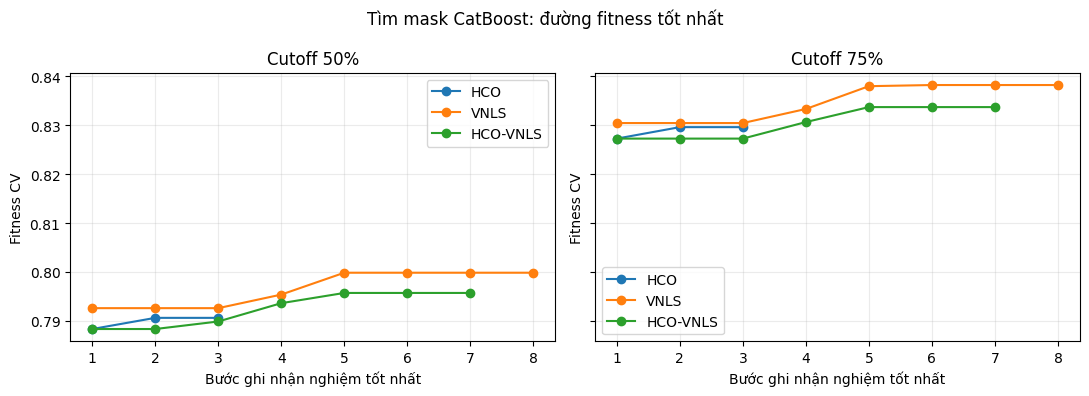

Cutoff 50%: đối chứng đủ cột AP=0.8489
  HCO: 17/38 cột; ΔAP validation=-0.0075; Accuracy=0.8079; Recall=0.5914
  VNLS: 16/38 cột; ΔAP validation=-0.0084; Accuracy=0.8048; Recall=0.5957
  HCO-VNLS: 17/38 cột; ΔAP validation=-0.0063; Accuracy=0.8037; Recall=0.5892
Cutoff 75%: đối chứng đủ cột AP=0.8979
  HCO: 17/38 cột; ΔAP validation=-0.0093; Accuracy=0.8679; Recall=0.6769
  VNLS: 15/38 cột; ΔAP validation=-0.0125; Accuracy=0.8691; Recall=0.6804
  HCO-VNLS: 16/38 cột; ΔAP validation=-0.0140; Accuracy=0.8589; Recall=0.6470


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, cutoff in zip(axes, (.50, .75)):
    for method, group in trajectory[trajectory.cutoff == cutoff].groupby('method', sort=False):
        axis.plot(group.step, group.best_fitness, marker='o', label=method)
    axis.set(title=f'Cutoff {cutoff:.0%}', xlabel='Bước ghi nhận nghiệm tốt nhất', ylabel='Fitness CV')
    axis.grid(alpha=.25)
    axis.legend()
fig.suptitle('Tìm mask CatBoost: đường fitness tốt nhất')
fig.tight_layout()
fig.savefig(HINH / 'hco_vnls_catboost_hoi_tu.png', dpi=160, bbox_inches='tight')
plt.show()
for cutoff, group in result.groupby('cutoff'):
    full = group.loc[group.method == 'Full features'].iloc[0]
    print(f'Cutoff {cutoff:.0%}: đối chứng đủ cột AP={full.average_precision_risk:.4f}')
    for _, row in group.loc[group.method != 'Full features'].iterrows():
        delta = row.average_precision_risk - full.average_precision_risk
        print(f'  {row.method}: {row.features}/{full.features} cột; ΔAP validation={delta:+.4f}; Accuracy={row.accuracy:.4f}; Recall={row.recall_risk:.4f}')

## 4. Rút ra điều gì, chưa rút ra điều gì?

**Kết quả pilot đã chạy:** cutoff 50%, CatBoost 80 cây đủ 38 cột đạt AP validation `0,8489`; HCO `0,8414`/17 cột, VNLS `0,8404`/16 cột, hybrid `0,8426`/17 cột. Cutoff 75%, đủ cột AP `0,8979`; HCO `0,8885`/17 cột, VNLS `0,8854`/15 cột, hybrid `0,8839`/16 cột. Tại 75%, Recall hybrid `0,6470` còn thấp hơn đối chứng `0,6847`. Như vậy **hybrid chưa thắng về AP hoặc Recall trên CatBoost** với một seed/budget 8; lợi ích duy nhất quan sát rõ là giảm số cột. Fitness CV của VNLS cao hơn có thể đến từ thưởng ít cột; không được tráo nó với AP validation.

Đây chỉ là **validation**, chưa đưa CatBoost vào test cũ và chưa dùng test để chọn lại tham số. Đối chứng CatBoost 240 cây trong notebook 04 là cấu hình khác và có AP `0,9019` tại 75%; không dùng nó để quy tác động riêng cho chọn cột của thí nghiệm 80 cây. Cần lặp seed, tăng ngân sách và thử alpha trước khi kết luận; muốn nói từng cột quan trọng cần thêm tần suất chọn và ablation theo nhóm. Một kỳ học mới chưa xem là cần thiết để kiểm tra khả năng khái quát.